# 微分与差分方程：从模型预测动态行为

对应笔记：`../../../微分or差分表示系统.md`。所有数据在本地合成，无需下载。先运行准备单元，再按顺序运行；修改各节开头参数即可重复实验。

目标：用图像和数值验证公式，并理解公式能解决什么问题。数值验证只覆盖所选案例，不代替数学证明。

**绘图约定：** 离散序列、采样测量与 DFT/FFT 频点采用竖杆图，样本之间不连线；连续时间或连续频率模型用曲线。各分量与结果分开成图，子图标题说明角色。较长序列会展示注明范围的局部，计算仍使用完整数据。

**学习方法：** 每节先读“要理解什么”与数学等式，把公式左右两边对应到代码及子图，再看计算误差或反例。重点是解释公式；实际应用用于帮助理解。数值近似、有限案例、理论恒等式和广义函数极限在各节分别说明。

In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal, integrate
from IPython.display import display, Markdown
rng = np.random.default_rng(42)
plt.rcParams.update({'figure.figsize': (9, 3), 'axes.grid': True})
# 图中使用英文标签，避免系统缺少中文字体；讲解和结果说明使用中文。
def graph(x, curves, xlabel='Sample index n', ylabel='Amplitude', *, kind='discrete', xlim=None):
    """每个分量独占子图；离散样本不连线，连续模型用曲线。"""
    import matplotlib.ticker as ticker
    count = len(curves)
    cols = min(2, count)
    rows = (count + cols - 1) // cols
    fig = plt.figure(figsize=(12 if cols == 2 else 10, 2.8 * rows), layout='constrained')
    grid = fig.add_gridspec(rows, cols)
    x = np.asarray(x)
    axes = []
    for i, (label, values) in enumerate(curves.items()):
        # 奇数个分量时，最后的结果图占满一行。
        slot = grid[i // cols, :] if count % 2 and i == count - 1 else grid[i // cols, i % cols]
        ax = fig.add_subplot(slot)
        values = np.asarray(values)
        color = f'C{i % 10}'
        if kind == 'discrete':
            marker, stems, baseline = ax.stem(x, values, basefmt='k-')
            plt.setp(marker, color=color, markersize=3 if len(x)>80 else 5)
            plt.setp(stems, color=color, linewidth=0.8 if len(x)>80 else 1.5)
            plt.setp(baseline, linewidth=0.5)
            if np.allclose(x, np.round(x)):
                ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=12, integer=True))
            if len(x) <= 20:
                ax.set_xticks(x)
                for xi, yi in zip(x, values):
                    if abs(yi) > max(1e-12, 0.05 * np.max(np.abs(values))):
                        ax.annotate(f'{yi:.3g}', (xi, yi), xytext=(0, 6 if yi >= 0 else -12),
                                    textcoords='offset points', ha='center', fontsize=8)
            ax.margins(y=0.2)
        elif kind == 'continuous':
            ax.plot(x, values, color=color, linewidth=1.5)
        else:
            raise ValueError('kind must be discrete or continuous')
        ax.set(title=label, xlabel=xlabel, ylabel=ylabel)
        if xlim is not None:
            ax.set_xlim(xlim)
        ax.grid(True, alpha=0.25)
        ax.set_axisbelow(True)
        axes.append(ax)
    plt.show()
    return axes

def err(a, b):
    return float(np.max(np.abs(np.asarray(a)-np.asarray(b))))


## 实验 1：一般微分方程、特解与齐次解

**要理解什么：** 理解特解加齐次解怎样同时满足微分方程与初值。

**要验证的数学形式（对照[原笔记](../../../微分or差分表示系统.md)）：**

$$
\begin{gathered}
\boxed{\frac{dy(t)}{dt}+ay(t)=Ku(t)} \\[6pt]
\boxed{y(t)=y_p(t)+y_h(t)=\frac Ka+Ae^{-at}}\quad(t>0)
\end{gathered}
$$

**符号与代码怎样对应：** 取 y(0)=y0，则 A=y0−K/a。`y_p` 是常数特解 K/a，`y_h` 是由初值决定的指数项；`solve_ivp` 从原微分方程独立求解。这里非零初值只讨论 t≥0，不假定负时间初始静止。

**怎样读图、怎样判断结果：** 分量图逐时刻相加得到 total；解析总解应与数值求解一致，t=0 时为 y0，长期趋向 K/a。本例 a=2、K=3、y0=1，故稳态 1.5、初始齐次项 −0.5。

**先预测，再改参数：** 把 y0 改成 3，预测总响应将从稳态上方衰减，而不是从下方上升。

**本例设置与适用范围：**

覆盖一至四节。研究 $y\prime+ay=K u(t)$，$y(0)=y_0$。对于 $t\ge0$，$y=K/a+(y_0-K/a)e^{-at}$。选取不同特解不会改变满足初值的总解。

数值解与解析解最大误差： 1.9401600326318658e-09


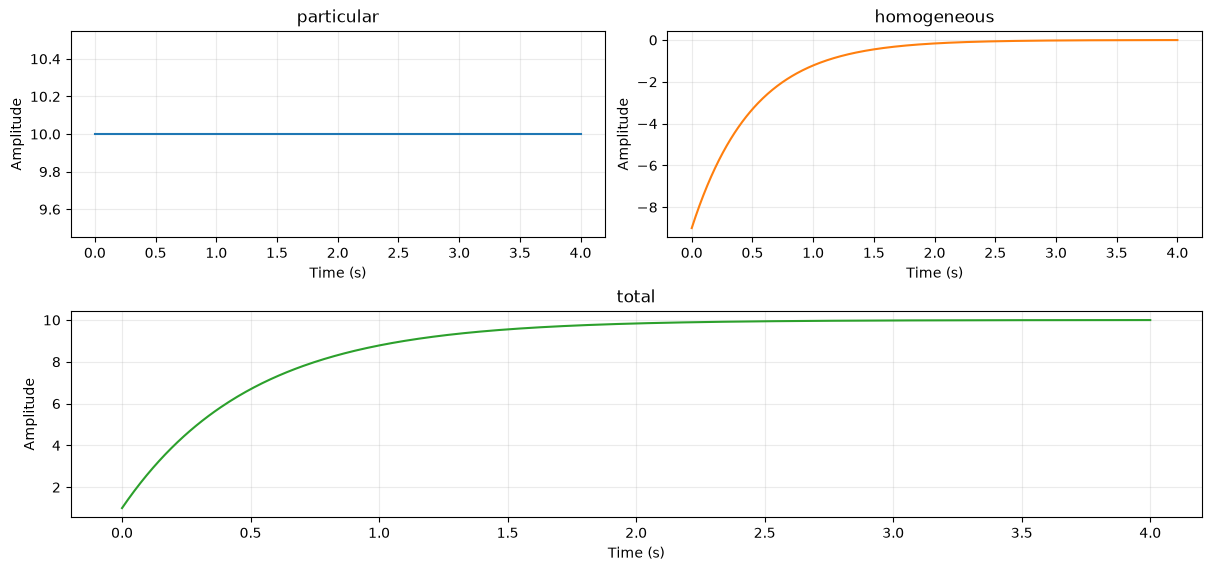

[<Axes: title={'center': 'particular'}, xlabel='Time (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'homogeneous'}, xlabel='Time (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'total'}, xlabel='Time (s)', ylabel='Amplitude'>]

In [39]:
a=2.; K=20.; y0=1.; t=np.linspace(0,4,500)
y_p=np.full_like(t,K/a); y_h=(y0-K/a)*np.exp(-a*t); total=y_p+y_h
sol=integrate.solve_ivp(lambda t,y:K-a*y,[0,4],[y0],t_eval=t,rtol=1e-9,atol=1e-11)
print('数值解与解析解最大误差：',err(sol.y[0],total))
# 另一特解：零状态阶跃响应；对应齐次项改为 y0 exp(-at)
assert np.allclose(total,K/a*(1-np.exp(-a*t))+y0*np.exp(-a*t))
graph(t,{'particular':y_p,'homogeneous':y_h,'total':total},'Time (s)',kind='continuous')

**观察与应用：** 特解决定受迫行为，初值决定瞬态。可描述热容量系统受恒定加热；增大 a 会缩短时间常数 1/a，同时改变稳态 K/a。把 y0 改成高于稳态的值，观察冷却过程。

## 实验 2：齐次指数、零输入与零状态

**要理解什么：** 理解自然指数为什么出现，并区分初值产生的响应与输入产生的响应。

**要验证的数学形式（对照[原笔记](../../../微分or差分表示系统.md)）：**

$$
\begin{gathered}
\frac{dy_h}{dt}+ay_h=0,\quad y_h=Ae^{st}\Rightarrow\boxed{s=-a} \\[6pt]
\boxed{y(t)=y_0e^{-at}+\frac Ka(1-e^{-at})}\quad(t\ge0)
\end{gathered}
$$

**符号与代码怎样对应：** 第一项 `zi` 是零输入响应，第二项 `zs` 是零初值下的阶跃驱动响应。`num` 是从原方程与同一初值计算的总解。s 在指数试探解中是参数，并非本节之外表示阶跃响应的函数 s(t)。

**怎样读图、怎样判断结果：** zi 从 y0 衰减，zs 从零上升，两项和应逐时刻等于 num。特解可有不同选法，但“零输入/零状态”由实验条件固定。

**先预测，再改参数：** 先令 K=0 只保留初值响应，再令 y0=0 只保留输入响应。

**本例设置与适用范围：**

覆盖二、三节。$e^{st}$ 代入得到 $s+a=0$。零输入响应由初值产生，零状态响应由输入产生；两者与“某个特解+齐次解”的选法要区分。

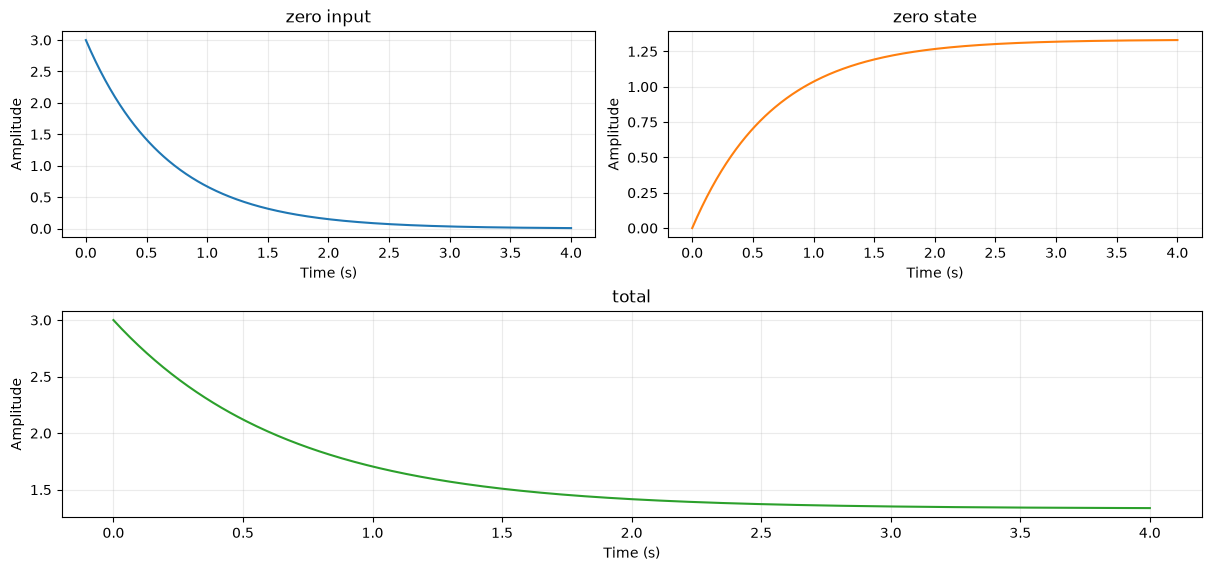

[<Axes: title={'center': 'zero input'}, xlabel='Time (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'zero state'}, xlabel='Time (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'total'}, xlabel='Time (s)', ylabel='Amplitude'>]

In [30]:
t=np.linspace(0,4,500); a=1.5; K=2.; y0=3.
zi=y0*np.exp(-a*t); zs=K/a*(1-np.exp(-a*t))
num=integrate.solve_ivp(lambda t,y:K-a*y,[0,4],[y0],t_eval=t,rtol=1e-9,atol=1e-11).y[0]
assert np.allclose(zi+zs,num,atol=1e-8)
graph(t,{'zero input':zi,'zero state':zs,'total':num},'Time (s)',kind='continuous')

**观察与应用：** 带电电容即使输入为零仍有输出，因此用卷积单独计算输出时，需要零初始状态；非零初值要额外加上自然响应。

## 实验 3：由阶跃求冲激、冲激筛选与卷积

**要理解什么：** 理解微分方程、阶跃响应、冲激响应与卷积描述的是同一个零状态系统。

**要验证的数学形式（对照[原笔记](../../../微分or差分表示系统.md)）：**

$$
\begin{gathered}
\boxed{h(t)=\frac{ds(t)}{dt}} \\[6pt]
\boxed{f(t)\delta(t)=f(0)\delta(t)} \\[6pt]
 \frac{dy}{dt}+ay=Kx(t),\quad s(t)=\frac Ka(1-e^{-at})u(t),\quad h(t)=Ke^{-at}u(t) \\[6pt]
\boxed{y(t)=x(t)*h(t)}
\end{gathered}
$$

**符号与代码怎样对应：** 此处 K 是系统输入增益，单位阶跃响应为 s。因 s(0)=0，乘积求导中的冲激项系数为零。代码先数值求导 s 对比 h，再用 x(t)=sin(2t) 分别执行 ODE 求解与卷积积分近似。

**怎样读图、怎样判断结果：** 连续内部点的阶跃导数应接近 h，卷积输出应接近 ODE 输出。代码中的 *dt 是积分权重，误差不必严格为零。两种计算均从零初值开始。

**先预测，再改参数：** 减小 dt 后比较两种误差；改变 K，h 与零状态输出应按比例缩放。

**本例设置与适用范围：**

覆盖第五节。输入增益为 $K$ 时，$s=K(1-e^{-at})/a$，$h=Ke^{-at}u(t)$。因 $s(0)=0$，求导中的 $s(0)\delta(t)$ 项为零。

阶跃求导内部误差： 4.515239824698369e-06
卷积与 ODE 误差： 0.0017011436955706172


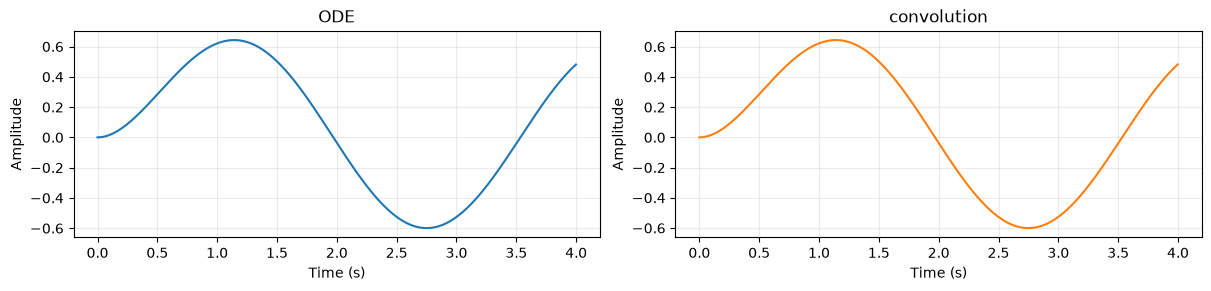

[<Axes: title={'center': 'ODE'}, xlabel='Time (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'convolution'}, xlabel='Time (s)', ylabel='Amplitude'>]

In [31]:
a=2.; K=1.7; dt=0.002; t=np.arange(0,4,dt)
s=K/a*(1-np.exp(-a*t)); h=K*np.exp(-a*t)
x=np.sin(2*t)
y_conv=np.convolve(x,h)[:len(t)]*dt
sol=integrate.solve_ivp(lambda tt,y:K*np.sin(2*tt)-a*y,[0,t[-1]],[0],t_eval=t,rtol=1e-9,atol=1e-11)
print('阶跃求导内部误差：',err(np.gradient(s,dt)[1:-1],h[1:-1]))
print('卷积与 ODE 误差：',err(y_conv,sol.y[0]))
graph(t,{'ODE':sol.y[0],'convolution':y_conv},'Time (s)',kind='continuous')

**观察与应用：** 同一个设备可用微分方程、冲激响应或卷积描述，三者相互校验。用阶跃测试识别设备后，可以预测其他输入下的输出。

## 实验 4：高阶特征根、重根与阻尼

**要理解什么：** 理解高阶方程为什么能转成代数求根，以及根怎样决定振荡和衰减。

**要验证的数学形式（对照[原笔记](../../../微分or差分表示系统.md)）：**

$$
\begin{gathered}
\boxed{\sum_{k=0}^{N}a_ks^k=0} \\[6pt]
\boxed{y_h(t)=A_1e^{s_1t}+\cdots+A_Ne^{s_Nt}} \\[6pt]
 s^2+2\zeta\omega_ns+\omega_n^2=0
\end{gathered}
$$

**符号与代码怎样对应：** 本例受迫系统取 y″+2ζω_n y′+ω_n²y=ω_n²u(t)，使阶跃稳态为 1；这与一般方程的系数形式一致。`np.roots` 求 s1、s2，模态图展示复指数实部相加得到真实自然响应。ζ=1 为重根，齐次项应为 (A+Bt)e^(−ω_n t)。

**怎样读图、怎样判断结果：** 小阻尼出现超调振荡；临界阻尼解析阶跃 1−(1+ω_n t)e^(−ω_n t) 应与数值阶跃一致。模态两分量相加应得到齐次响应。

**先预测，再改参数：** 把 ζ 从 0.2 逐渐改到 1，比较根的虚部、波形振荡与衰减速度。

**本例设置与适用范围：**

覆盖第六节。$y\prime\prime+2\zeta\omega_n y\prime+\omega_n^2y=\omega_n^2u(t)$。特征根决定衰减、振荡；临界重根的齐次解含 $te^{-\omega_n t}$。

阻尼比 0.2 特征根 [-0.6+2.93938769j -0.6-2.93938769j] 阶跃峰值 1.5266166205383018
阻尼比 1.0 特征根 [-3.+3.7252903e-08j -3.-3.7252903e-08j] 阶跃峰值 0.9999951055628672
阻尼比 1.8 特征根 [-9.88998886 -0.91001114] 阶跃峰值 0.9883625864136769


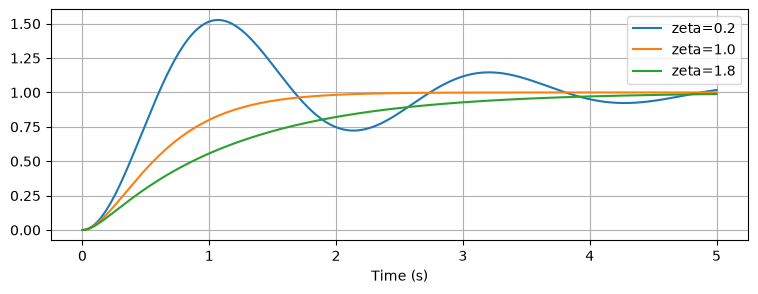

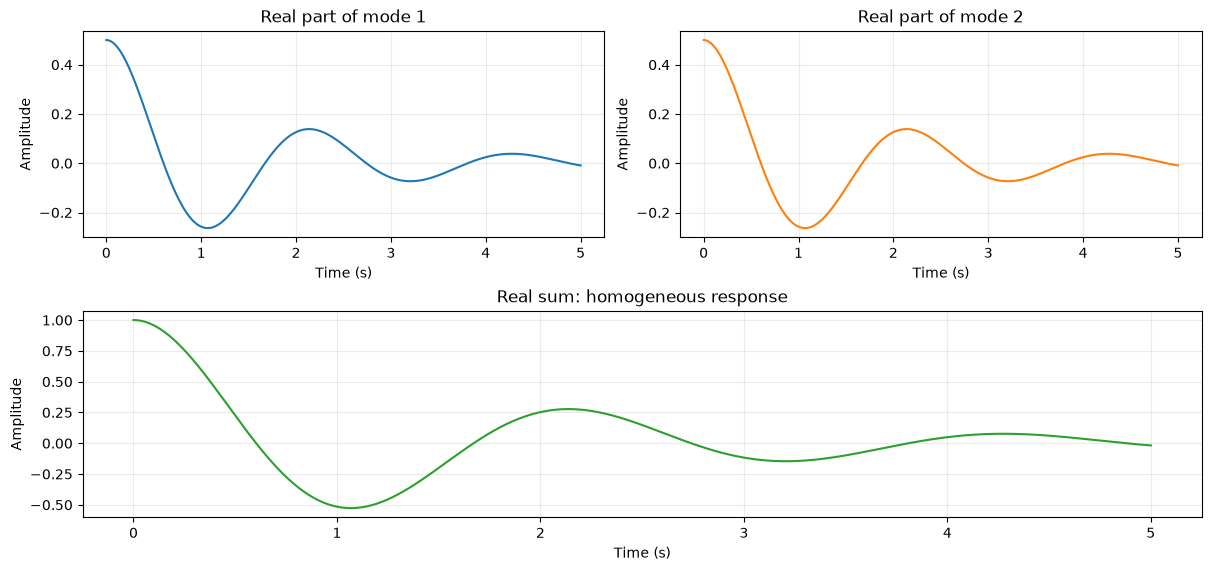

[<Axes: title={'center': 'Real part of mode 1'}, xlabel='Time (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'Real part of mode 2'}, xlabel='Time (s)', ylabel='Amplitude'>,
 <Axes: title={'center': 'Real sum: homogeneous response'}, xlabel='Time (s)', ylabel='Amplitude'>]

In [32]:
wn=3.; t=np.linspace(0,5,800)
for zeta in [0.2,1.,1.8]:
    den=[1,2*zeta*wn,wn**2]
    _,y=signal.step(signal.TransferFunction([wn**2],den),T=t)
    print('阻尼比',zeta,'特征根',np.roots(den),'阶跃峰值',max(y))
    plt.plot(t,y,label=f'zeta={zeta}')
plt.legend(); plt.xlabel('Time (s)'); plt.show()
critical=1-(1+wn*t)*np.exp(-wn*t)
_,numeric=signal.step(signal.TransferFunction([wn**2],[1,2*wn,wn**2]),T=t)
assert np.allclose(critical,numeric)
# 非重根：由初值解出两项指数的系数。
roots=np.roots([1,2*0.2*wn,wn**2]); A=np.linalg.solve(np.array([[1,1],roots]),[1,0])
yh=np.real(A[0]*np.exp(roots[0]*t)+A[1]*np.exp(roots[1]*t))
graph(t,{'Real part of mode 1':np.real(A[0]*np.exp(roots[0]*t)),
    'Real part of mode 2':np.real(A[1]*np.exp(roots[1]*t)),
    'Real sum: homogeneous response':yh},'Time (s)',kind='continuous')

**观察与应用：** 悬架、机械指针和控制回路需要在响应速度与振荡之间权衡。临界阻尼无振铃；不能把两个相同指数简单相加当成重根的通解。

## 实验 5：一般差分方程与逐样本递推

**要理解什么：** 理解差分方程是逐样本执行的规则，冲激响应可直接由这条规则生成。

**要验证的数学形式（对照[原笔记](../../../微分or差分表示系统.md)）：**

$$
\begin{gathered}
\boxed{\sum_{k=0}^{N}a_ky[n-k]=\sum_{k=0}^{M}b_kx[n-k]} \\[6pt]
\boxed{y[n]=x[n]+\alpha y[n-1]} \\[6pt]
\boxed{h[n]=\alpha^n u[n]}
\end{gathered}
$$

**符号与代码怎样对应：** `prev` 是上一输出，输入 `delta` 仅首项为 1；循环直接执行 h[n]=δ[n]+αh[n−1]。`lfilter([1],[1,-alpha],delta)` 是同一方程的库实现。后半段用二阶例子检查原方程左右之差。

**怎样读图、怎样判断结果：** 前三个冲激响应应为 1、α、α²；递推、解析与库函数结果一致。二阶残差应接近零，表示输出确实满足指定输入输出关系。

**先预测，再改参数：** 把 α 改为负数，预测冲激响应将交替正负；注意分母 [1,−α] 的符号来自移项。

**本例设置与适用范围：**

覆盖第七、八节。$y[n]=x[n]+\alpha y[n-1]$，初始 $y[-1]=0$。一般形式由分子 b 与分母 a 的延迟系数表示。

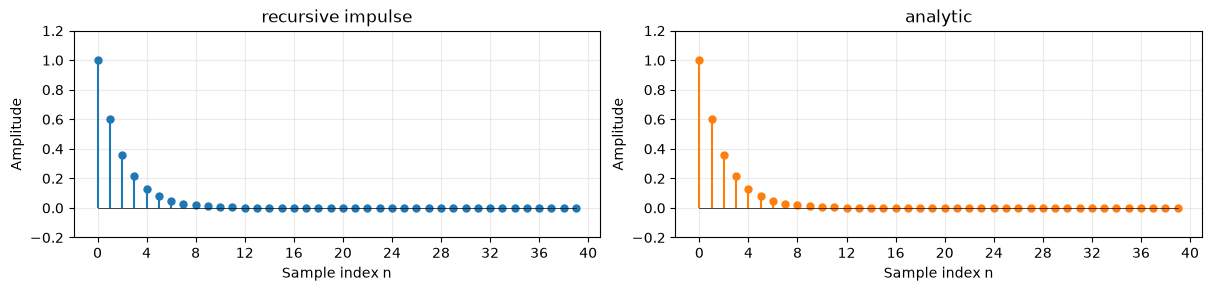

二阶差分方程残差： 5.551115123125783e-17


In [33]:
alpha=0.6; N=40; delta=np.r_[1.,np.zeros(N-1)]
h=np.zeros(N); prev=0.
for n in range(N):
    h[n]=delta[n]+alpha*prev
    prev=h[n]
assert np.allclose(h,alpha**np.arange(N))
assert np.allclose(h,signal.lfilter([1],[1,-alpha],delta))
graph(np.arange(N),{'recursive impulse':h,'analytic':alpha**np.arange(N)},kind='discrete')
x=rng.normal(size=N)
y=signal.lfilter([0.2,0.1],[1,-0.7,0.1],x)
residual=y[2:]-0.7*y[1:-1]+0.1*y[:-2]-0.2*x[2:]-0.1*x[1:-1]
print('二阶差分方程残差：',max(abs(residual)))

**观察与应用：** 可用很少的存储逐样本实现数字滤波器，适合微控制器。改变 alpha 看衰减；反馈系数的正负号应从方程移项确定。

## 实验 6：离散特征根与高阶自然响应

**要理解什么：** 理解离散自然响应的指数形式与特征多项式。

**要验证的数学形式（对照[原笔记](../../../微分or差分表示系统.md)）：**

$$
\begin{gathered}
\boxed{y_h[n]=Az^n},\quad z^{n-k}=z^nz^{-k} \\[6pt]
\boxed{\sum_{k=0}^{N}a_kz^{N-k}=0} \\[6pt]
\boxed{y_h[n]=A_1z_1^n+\cdots+A_Nz_N^n}
\end{gathered}
$$

**符号与代码怎样对应：** 例子 y[n]−1.1y[n−1]+0.28y[n−2]=0 的根为 0.7 与 0.4。`A` 由 y[0]=1、y[1]=0.3 解出；两条模态分别为 A1*z1**n 与 A2*z2**n。后半段另检验重根形式 (A+Bn)rⁿ。

**怎样读图、怎样判断结果：** 两条模态逐样本相加等于直接递推；注意某个模态系数可能为负。重根候选解代入原差分方程的残差应接近零。

**先预测，再改参数：** 修改初始两项，根不变但 A1、A2 改变；比较“系统系数决定根”和“初值决定幅度”的分工。

**本例设置与适用范围：**

覆盖第九节。$z^{n-k}=z^nz^{-k}$。对 $y[n]-1.1y[n-1]+0.28y[n-2]=0$，特征多项式为 $z^2-1.1z+0.28$。

特征根： [0.7 0.4] 模态系数： [-0.33333333  1.33333333] 误差： 5.551115123125783e-17


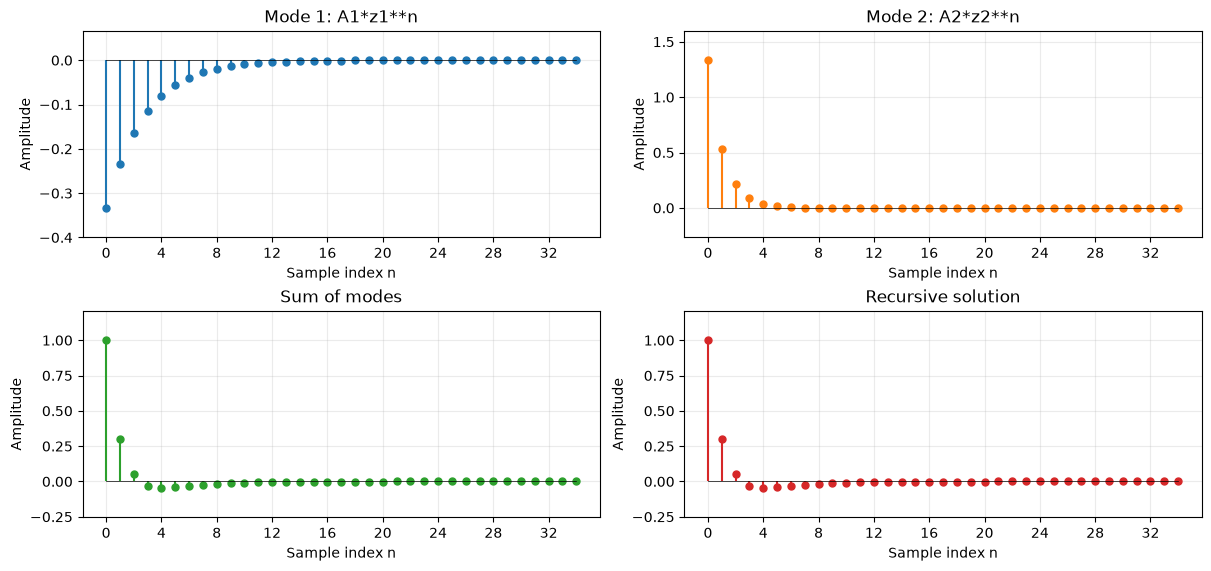

重根解残差： 1.6653345369377348e-16


In [34]:
roots=np.roots([1,-1.1,0.28]); n=np.arange(35)
y=np.zeros(len(n)); y[:2]=[1,0.3]
for i in range(2,len(n)):
    y[i]=1.1*y[i-1]-0.28*y[i-2]
A=np.linalg.solve(np.array([[1,1],roots]),y[:2])
y_modes=A[0]*roots[0]**n+A[1]*roots[1]**n
print('特征根：',roots,'模态系数：',A,'误差：',err(y,y_modes))
assert np.allclose(y,y_modes)
graph(n,{'Mode 1: A1*z1**n':A[0]*roots[0]**n,
    'Mode 2: A2*z2**n':A[1]*roots[1]**n,'Sum of modes':y_modes,'Recursive solution':y},kind='discrete')
# 重根 r 的二阶齐次解应为 (A+B*n)*r**n。
r=0.7; repeated=(1+0.2*n)*r**n
print('重根解残差：',max(abs(repeated[2:]-2*r*repeated[1:-1]+r*r*repeated[:-2])))

**观察与应用：** 根的模小于 1 时这些自然模态衰减；负根会交替、复根会振荡。用于判断数字控制器或滤波器的瞬态；零根、退化阶数需单独处理，不能随意除以零。

## 实验 7：差分特解、初值、阶跃与 alpha=1

**要理解什么：** 理解离散特解与初值项，以及阶跃响应为什么是几何级数。

**要验证的数学形式（对照[原笔记](../../../微分or差分表示系统.md)）：**

$$
\begin{gathered}
\boxed{y[n]=y_p[n]+y_h[n]} \\[6pt]
\boxed{s[n]=\frac{1-\alpha^{n+1}}{1-\alpha}u[n]}\ (\alpha\ne1) \\[6pt]
 s[n]=(n+1)u[n]\ (\alpha=1) \\[6pt]
\boxed{h[n]=s[n]-s[n-1]}
\end{gathered}
$$

**符号与代码怎样对应：** 取 x[n]=u[n]、给定 y[−1]。代码 `zs` 是初始静止阶跃响应 s[n]；`zi=alpha**(n+1)*yminus1` 是初值产生的响应；逐样本循环得到总输出。α≠1 的常数特解可取 1/(1−α)，它不等同于整条零状态响应。

**怎样读图、怎样判断结果：** 每组图中 zs+zi 应等于 total，差分 zs 应恢复 αⁿ。α=1 时输出随 n 增长，必须用单独公式，不能除以 1−α。

**先预测，再改参数：** 把 yminus1 改为 0，仅剩阶跃响应；把 α 改得更接近 1，预测记忆与稳态增益增加。

**本例设置与适用范围：**

覆盖第十节。$\alpha\ne1$ 时，常值特解 $1/(1-\alpha)$，$s[n]=(1-\alpha^{n+1})/(1-\alpha)$。$\alpha=1$ 时 $s[n]=n+1$。

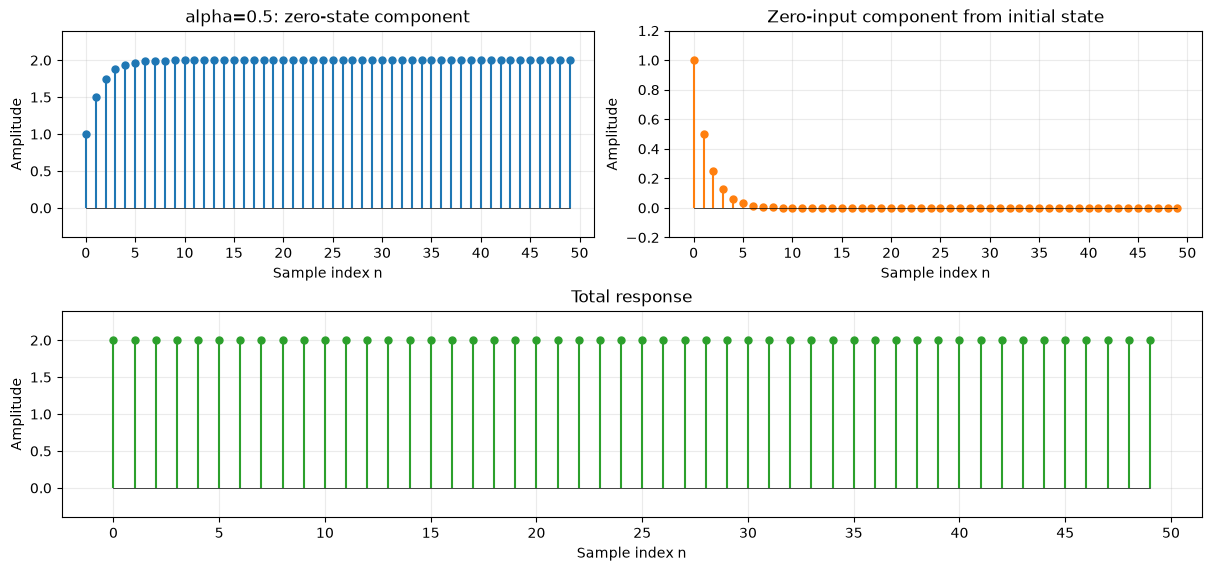

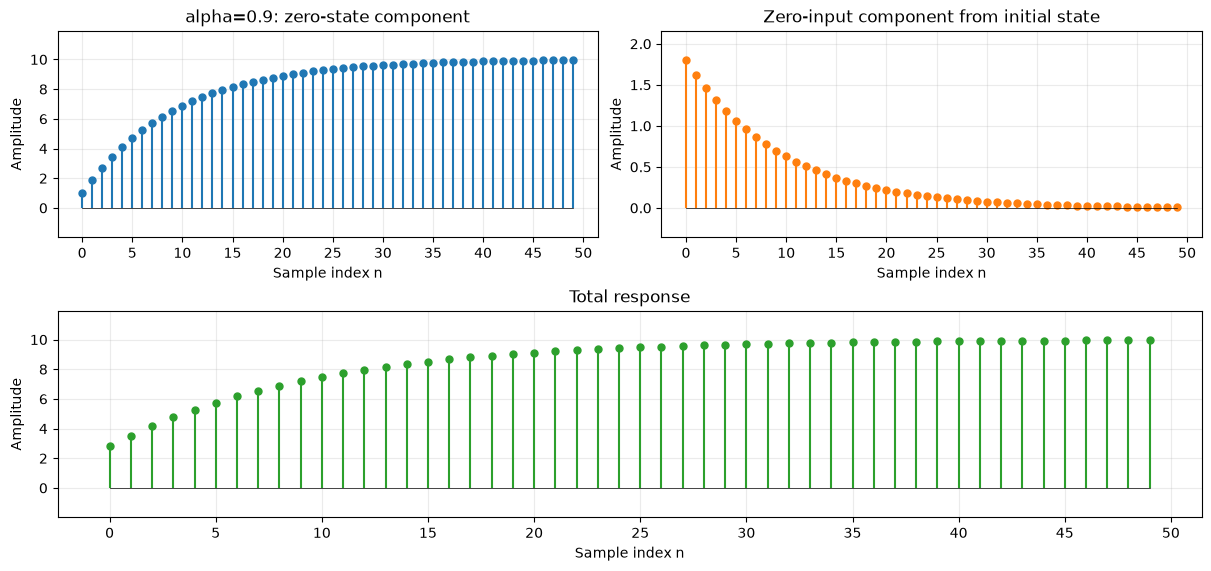

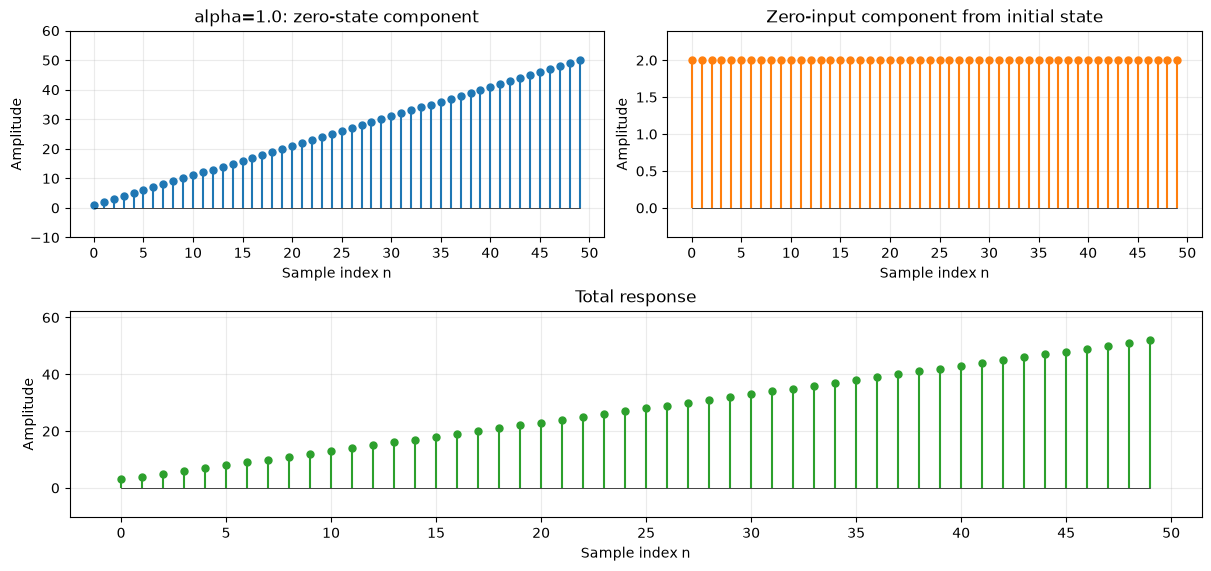

In [35]:
n=np.arange(50); yminus1=2.
for alpha in [0.5,0.9,1.]:
    zs=n+1. if alpha==1 else (1-alpha**(n+1))/(1-alpha)
    zi=alpha**(n+1)*yminus1
    y=[]; prev=yminus1
    for _ in n:
        prev=1+alpha*prev; y.append(prev)
    assert np.allclose(y,zs+zi)
    recovered_h=np.diff(np.r_[0,zs])
    assert np.allclose(recovered_h,alpha**n)
    graph(n,{f'alpha={alpha}: zero-state component':zs,
        'Zero-input component from initial state':zi,'Total response':np.asarray(y)},kind='discrete')

**观察与应用：** alpha 接近 1 时记忆很长、稳态增益很大；alpha=1 是累加器，不能代入分母为零的公式。可理解累计用量与“逐渐遗忘”的统计量之别。

## 实验 8：实际例子：指数平滑与连续模型的联系

**要理解什么：** 用温度测量理解连续动态模型怎样得到数字递推。

**要验证的数学形式（对照[原笔记](../../../微分or差分表示系统.md)）：**

$$
\begin{gathered}
\tau\frac{dy}{dt}+y=x \\[6pt]
\boxed{y[k+1]=\alpha y[k]+(1-\alpha)x[k]},\quad\alpha=e^{-\Delta t/\tau}
\end{gathered}
$$

**符号与代码怎样对应：** 这是笔记一阶微分方程与差分方程的应用推导：采样间 x 保持常数时，单个区间精确解为 y(t+dt)=e^(−dt/τ)y(t)+(1−e^(−dt/τ))x。`measured` 是 x[k]，`filtered` 是 y[k]；索引为下一时刻更新。

**怎样读图、怎样判断结果：** 测量图=真实温度样本+噪声；递推结果抖动减弱而在温度跳变后滞后。静稳区间的滤波 RMSE 应小于原测量 RMSE，但整个跳变区间不能仅用同一结论概括。

**先预测，再改参数：** 增大 τ 会增大 α，旧输出权重变大，预测噪声更小、跟随更慢。

**本例设置与适用范围：**

温度传感器的归一化模型 $\tau y\prime+y=x$。采样间输入保持常值时，精确递推 $y_{k+1}=\alpha y_k+(1-\alpha)x_k$，$\alpha=e^{-\Delta t/\tau}$。

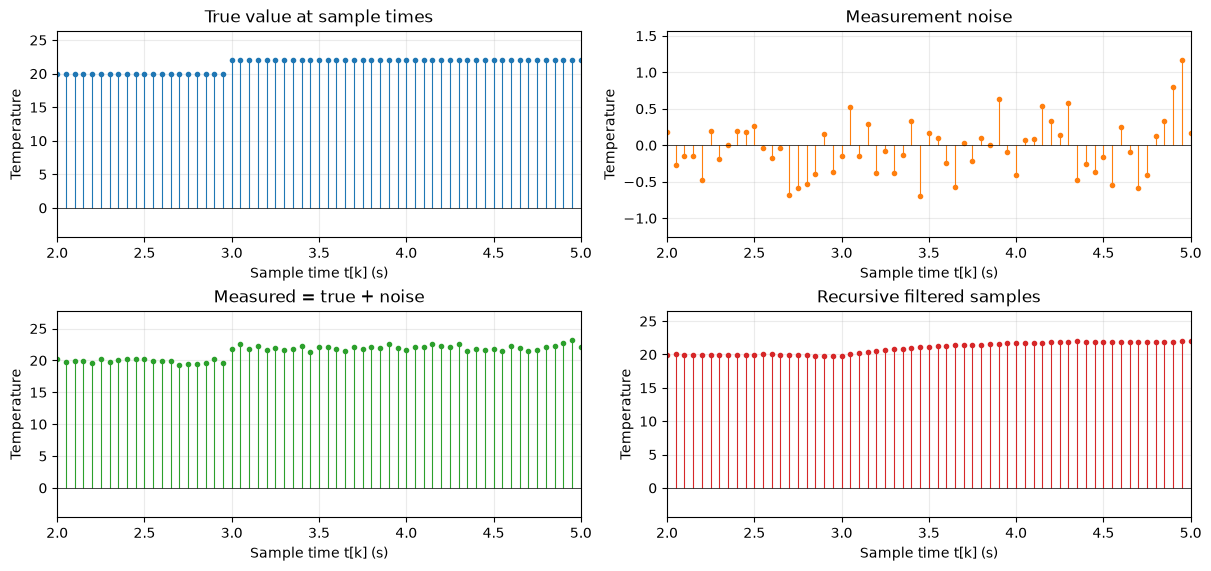

静稳段测量/滤波 RMSE： 0.27666097418697444 0.04100402925650748


In [36]:
dt=0.05; tau=0.5; n=np.arange(200); t=n*dt
true=20+2*(t>=3); measured=true+0.4*rng.normal(size=len(t))
alpha=np.exp(-dt/tau); filtered=np.empty(len(t)); filtered[0]=measured[0]
for k in range(len(t)-1):
    filtered[k+1]=alpha*filtered[k]+(1-alpha)*measured[k]
graph(t,{'True value at sample times':true,'Measurement noise':measured-true,
    'Measured = true + noise':measured,'Recursive filtered samples':filtered},
    'Sample time t[k] (s)','Temperature',kind='discrete',xlim=(2,5))
quiet=(t>1)&(t<2.8)
print('静稳段测量/滤波 RMSE：',np.sqrt(np.mean((measured[quiet]-true[quiet])**2)),np.sqrt(np.mean((filtered[quiet]-true[quiet])**2)))

**观察与应用：** 归一化后的稳态增益是 1，适合读数平滑。改变 tau 会影响噪声和跟随速度。这里 y[k+1] 对应下一采样时刻，不能与使用当前输入更新当前输出的另一种索引约定混用。

## 实验记录

每次选一个参数，记录：原值、新值、图像变化、指标变化、可以解决的实际问题、模型的适用条件。先预测结果，再运行验证。